RL for logistics Center V2

In [112]:
# Defining an enviroment for the agent (logistics center)
import numpy as np
import random as rd
import copy as cp

# The logistics center is created according to the docks number and SKU numbers
# SKU number = the different number of products avaible in the warehouse
# docker number = the different number of docks in the warehouse
class logistics_center:

    def __init__(self, num_docks = 3, num_SKU = 3, num_deliveries = 4):
        self.num_docks = num_docks
        self.num_SKU = num_SKU
        self.num_deliveries = num_deliveries
        self.my_table = Qtable(lr = 0.02, gamma = 1)

    # the warehouse is a matrix, that contains zeros as "empty space", ones which are the docks, and twos, which are the the SKU positions
    def create_warehouse(self):

        warehouse = np.zeros((self.num_docks, (self.num_docks + 2)))

        for i in range(self.num_docks):
            warehouse[i,0] = 1

        j = 0 

        while j < self.num_SKU:
            a , b = rd.randint(0, (self.num_docks -1)), rd.randint(1, (self.num_docks + 1))
            if warehouse[a,b] == 0:
                warehouse[a, b] = 2
                j += 1

        return warehouse

    # This function is responsible for reseting the enviroment for a new episode to start
    def reset(self):
        self.warehouse = self.create_warehouse()
        self.state = State(self.warehouse, self.num_deliveries)
        self.agent = Agent(self.warehouse, self.state)

    def reward(self):
        if self.agent.invalid_delivery:
            return -20

        delivery = self.agent.current_chosen_delivery

        if self.state.current_episode_time <= self.state.deadline[delivery]:
            return 20

        else:
            return -50


    #here is where we define the episode
    def episode(self):
        self.reset()
        p_state = cp.deepcopy(self.state)
        actions_list =[self.agent.pick_delivery1, self.agent.pick_delivery2, self.agent.pick_delivery3, self.agent.pick_delivery4]
        b = 0
        total_reward_per_episode = 0
        
        while True:
            done = False
            a = self.my_table.choose_action(state=self.state)
            actions_list[a]()
    
            if self.agent.invalid_delivery:
                reward = self.reward()
                total_reward_per_episode += reward

                self.my_table.update_q_table(
                    state=p_state,
                    action=a,
                    reward=reward,
                    next_state=self.state,
                    done=done
                )

                p_state = cp.deepcopy(self.state)

                print("Invalid delivery")
                print("Reward:", reward)

                continue
            
            agent_position = self.state.position
            sku_position = self.state.pick_SKUs[self.agent.current_chosen_delivery]
            dock_position = self.state.delivery_docks[self.agent.current_chosen_delivery]
            distance_a_to_sku = abs(agent_position[0] - sku_position[0]) + abs(agent_position[1] - sku_position[1])
            distance_sku_to_dd = abs(sku_position[0] - dock_position[0]) + abs(sku_position[1] - dock_position[1])
            total_distance = distance_a_to_sku + distance_sku_to_dd
            time = self.state.current_episode_time + total_distance

            if time <= self.state.deadline[self.agent.current_chosen_delivery]:
                b += 1 
                self.state.current_episode_time = time
                self.state.status[self.agent.current_chosen_delivery] = 0
                self.state.position = [int(x) for x in dock_position]
                print(f"Delivery on time: {b}")

            else:
                self.state.current_episode_time = time
                self.state.status[self.agent.current_chosen_delivery] = 0
                self.state.position = [int(x) for x in dock_position]
                print(f"Delivery out of time")

            reward = self.reward()

            if np.array_equal(self.state.status, np.array([0, 0, 0, 0])):
                print("All deliveries were done")
                done = True

            self.my_table.update_q_table(
                state=p_state,
                action=a,
                reward=reward,
                next_state=self.state,
                done=done
            )

            total_reward_per_episode += reward
            
            if done:
                self.my_table.epsilon = max(self.my_table.epsilon*self.my_table.epsilon_decay, self.my_table.epsilon_min)
                break

            p_state = cp.deepcopy(self.state)
            
            print("Position:", self.state.position)
            print("Reward:", reward)
            print("Epsilon:", self.my_table.epsilon)
        return total_reward_per_episode, b

In [123]:
import itertools


class State:

    def __init__(self, warehouse_created, num_deliveries):

        self.num_deliveries = num_deliveries

        # Posições vazias para o agente começar
        empty_positions = np.argwhere(
            warehouse_created == 0
        )

        self.position = empty_positions[
            np.random.randint(len(empty_positions))
        ].copy()

        # Posições dos SKUs
        sku_positions = np.argwhere(
            warehouse_created == 2
        )

        # Posições das docas
        dock_positions = np.argwhere(
            warehouse_created == 1
        )

        # Sorteia os SKUs das entregas
        self.pick_SKUs = np.array([
            sku_positions[
                np.random.randint(len(sku_positions))
            ].copy()
            for _ in range(num_deliveries)
        ])

        # Sorteia as docas das entregas
        self.delivery_docks = np.array([
            dock_positions[
                np.random.randint(len(dock_positions))
            ].copy()
            for _ in range(num_deliveries)
        ])

        # 1 = entrega ainda disponível
        # 0 = entrega concluída
        self.status = np.ones(
            num_deliveries,
            dtype=int
        )

        # Tempo atual do episódio
        self.current_episode_time = 0

        # Cria deadlines factíveis
        self.deadline = self.generate_deadlines()

    def calculate_delivery_time(self, delivery):

        # Agente -> SKU
        agent_to_sku = np.sum(
            np.abs(
                self.position -
                self.pick_SKUs[delivery]
            )
        )

        # SKU -> doca
        sku_to_dock = np.sum(
            np.abs(
                self.pick_SKUs[delivery] -
                self.delivery_docks[delivery]
            )
        )

        return agent_to_sku + sku_to_dock

    def generate_deadlines(self):

        # Testa as 24 ordens possíveis
        for order in itertools.permutations(
            range(self.num_deliveries)
        ):

            current_position = self.position.copy()
            current_time = 0

            deadlines = np.zeros(
                self.num_deliveries,
                dtype=int
            )

            for delivery in order:

                # Posição atual -> SKU
                time_to_sku = np.sum(
                    np.abs(
                        current_position -
                        self.pick_SKUs[delivery]
                    )
                )

                # SKU -> doca
                time_to_dock = np.sum(
                    np.abs(
                        self.pick_SKUs[delivery] -
                        self.delivery_docks[delivery]
                    )
                )

                # Tempo dessa entrega
                delivery_time = (
                    time_to_sku +
                    time_to_dock
                )

                # Tempo acumulado
                current_time += delivery_time

                # Deadline da entrega
                deadlines[delivery] = current_time

                # Depois da entrega, o agente está na doca
                current_position = (
                    self.delivery_docks[delivery].copy()
                )

            # Essa ordem é sempre factível,
            # pois os deadlines foram construídos
            # exatamente com base nela.
            return deadlines

        raise ValueError(
            "Não foi possível gerar os deadlines."
        )

In [114]:
# defining the agent, which is going to have actions and get the state and warehouse created
# the agent can move upwards, downwards and go to the left or to the right, movimentation implemented via matrix 
# we also change the state here, by moving the agent, the dealine is changed as well as the has_SKU state

class Agent():

    def __init__(self, warehouse_created, state):

        self.warehouse_created = warehouse_created
        self.state = state 
        self.invalid_delivery = False

    def pick_delivery1(self):
        self.invalid_delivery = False

        if self.state.status[0] == 1:
            self.current_chosen_delivery = 0
            self.SKU_requisition = self.state.pick_SKUs[0]
            self.delivery_dock = self.state.delivery_docks[0]
            return 0

        self.invalid_delivery = True
        return None


    def pick_delivery2(self):
        self.invalid_delivery = False

        if self.state.status[1] == 1:
            self.current_chosen_delivery = 1
            self.SKU_requisition = self.state.pick_SKUs[1]
            self.delivery_dock = self.state.delivery_docks[1]
            return 1

        self.invalid_delivery = True
        return None

    def pick_delivery3(self):
        self.invalid_delivery = False

        if self.state.status[2] == 1:
            self.current_chosen_delivery = 2
            self.SKU_requisition = self.state.pick_SKUs[2]
            self.delivery_dock = self.state.delivery_docks[2]
            return 2

        self.invalid_delivery = True
        return None
    
    def pick_delivery4(self):
        self.invalid_delivery = False

        if self.state.status[3] == 1:
            self.current_chosen_delivery = 3
            self.SKU_requisition = self.state.pick_SKUs[3]
            self.delivery_dock = self.state.delivery_docks[3]
            return 3

        self.invalid_delivery = True
        return None

In [115]:
# the first model we will try it's gonna be Q-Learning

class Qtable():

    def __init__(self, lr, gamma, epsilon=1.0, epsilon_decay=0.995, epsilon_min=0.01):
        self.lr = lr
        self.gamma = gamma

        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

        self.q_table = {}

    def get_q_values(self, state):

        state_key = self.state_to_key(state)

        if state_key not in self.q_table:
            self.q_table[state_key] = np.zeros(4)

        return self.q_table[state_key]

    def state_to_key(self, state):

        position = tuple(state.position)

        deliveries = tuple(
            (
                tuple(state.pick_SKUs[i]),
                tuple(state.delivery_docks[i]),
                state.deadline[i]
            )
            for i in range(len(state.status))
            if state.status[i] == 1
        )

        current_episode_time = state.current_episode_time

        return (
            position,
            deliveries,
            current_episode_time
        )

    def choose_action(self, state):

        q_values = self.get_q_values(state)

        possible_actions = []

        for i in range(len(state.status)):
            if state.status[i] == 1:
                possible_actions.append(i)

        # Exploração
        if np.random.rand() < self.epsilon:
            action = np.random.choice(possible_actions)

        # Aproveitamento
        else:
            possible_q_values = q_values[possible_actions]
            action = possible_actions[np.argmax(possible_q_values)]

        return action

    def update_q_table(self, state, action, reward, next_state, done):

        current_q_values = self.get_q_values(state)
        next_q_values = self.get_q_values(next_state)

        current_q = current_q_values[action]

        if done:

            target = reward

        else:

            possible_next_actions = []

            for i in range(len(next_state.status)):
                if next_state.status[i] == 1:
                    possible_next_actions.append(i)

            if possible_next_actions:
                max_next_q = np.max(next_q_values[possible_next_actions])
            else:
                max_next_q = 0

            target = reward + self.gamma * max_next_q

        self.q_table[self.state_to_key(state)][action] = (
            current_q + self.lr * (target - current_q)
        )

In [124]:
env = logistics_center()
rewards_list = []
deliveries_on_time_list = []
env.my_table.epsilon_decay = 0.999

for episode in range(7000):
    print(f"\n--- Episode {episode + 1} ---")
    a, b = env.episode()
    rewards_list.append(a)
    deliveries_on_time_list.append(b)



--- Episode 1 ---
Delivery on time: 1
Position: [1, 0]
Reward: 20
Epsilon: 1.0
Delivery out of time
Position: [2, 0]
Reward: -50
Epsilon: 1.0
Delivery on time: 2
Position: [1, 0]
Reward: 20
Epsilon: 1.0
Delivery out of time
All deliveries were done

--- Episode 2 ---
Delivery on time: 1
Position: [0, 0]
Reward: 20
Epsilon: 0.999
Delivery on time: 2
Position: [2, 0]
Reward: 20
Epsilon: 0.999
Delivery on time: 3
Position: [2, 0]
Reward: 20
Epsilon: 0.999
Delivery on time: 4
All deliveries were done

--- Episode 3 ---
Delivery on time: 1
Position: [0, 0]
Reward: 20
Epsilon: 0.998001
Delivery on time: 2
Position: [2, 0]
Reward: 20
Epsilon: 0.998001
Delivery on time: 3
Position: [1, 0]
Reward: 20
Epsilon: 0.998001
Delivery out of time
All deliveries were done

--- Episode 4 ---
Delivery on time: 1
Position: [2, 0]
Reward: 20
Epsilon: 0.997002999
Delivery on time: 2
Position: [0, 0]
Reward: 20
Epsilon: 0.997002999
Delivery on time: 3
Position: [1, 0]
Reward: 20
Epsilon: 0.997002999
Delivery

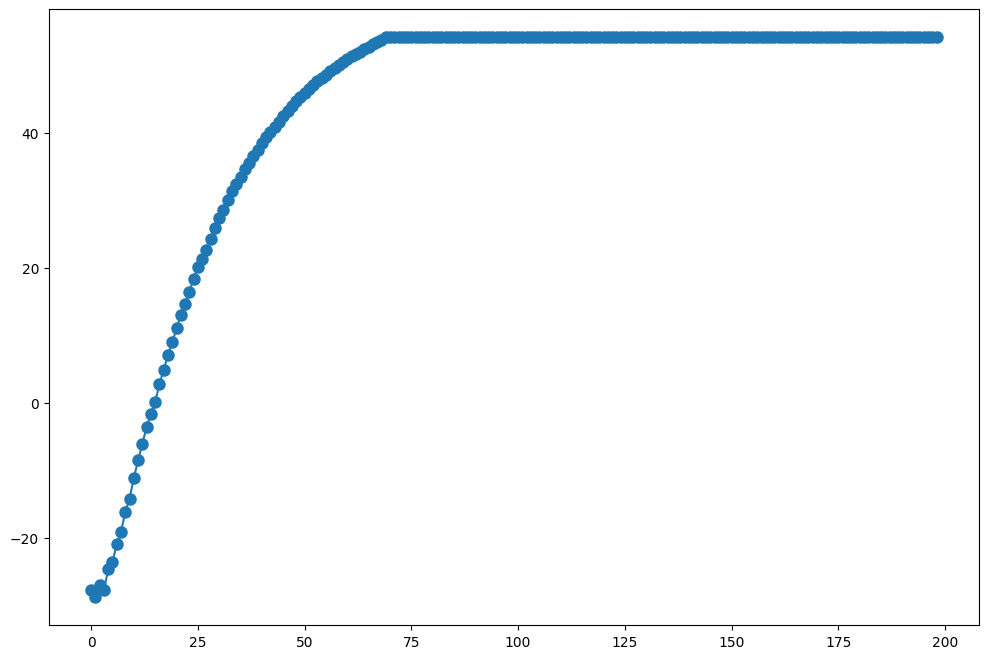

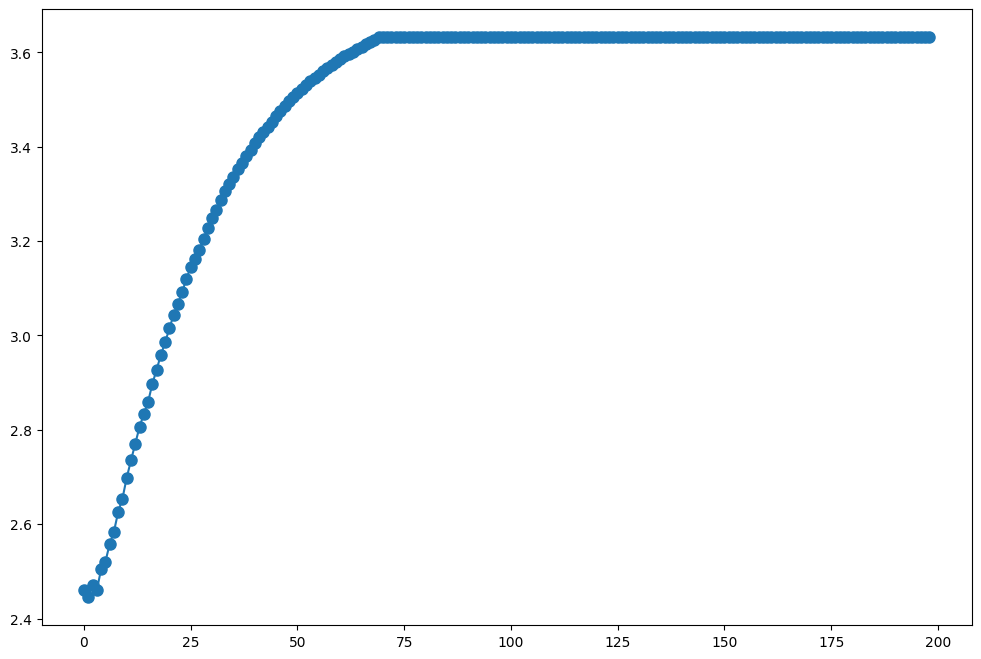

In [125]:
import matplotlib.pyplot as plt

mean_rewards = []
mean_deliveries = []
for i in range(100, 20000, 100):
    mean_reward = sum(rewards_list[:i])/len(rewards_list[:i])
    mean_deliverie = sum(deliveries_on_time_list[:i])/len(deliveries_on_time_list[:i])
    mean_rewards.append(mean_reward)
    mean_deliveries.append(mean_deliverie)


plt.figure(figsize=(12,8))
plt.plot(range(len(mean_rewards)), mean_rewards, marker = 'o', markersize = 8)
plt.figure(figsize=(12,8))
plt.plot(range(len(mean_deliveries)), mean_deliveries, marker = 'o', markersize = 8)

Depois, adaptar para que o agent so possa se movimentar pelos zeros, melhorar lógica da criação de deadlines para que todos sejam "possíveis" num dia de trabalho

In [126]:
import random as rd
import matplotlib.pyplot as plt

random_rewards_list = []
random_deliveries_on_time_list = []

# Teste com escolha aleatória
for episode in range(20000):

    env.reset()

    total_reward = 0
    deliveries_on_time = 0

    while True:

        # Escolhe aleatoriamente uma entrega ainda disponível
        possible_actions = [
            i for i in range(len(env.state.status))
            if env.state.status[i] == 1
        ]

        action = rd.choice(possible_actions)

        # Executa a entrega
        actions_list = [
            env.agent.pick_delivery1,
            env.agent.pick_delivery2,
            env.agent.pick_delivery3,
            env.agent.pick_delivery4
        ]

        actions_list[action]()

        agent_position = env.state.position
        sku_position = env.state.pick_SKUs[action]
        dock_position = env.state.delivery_docks[action]

        distance_a_to_sku = (
            abs(agent_position[0] - sku_position[0])
            + abs(agent_position[1] - sku_position[1])
        )

        distance_sku_to_dd = (
            abs(sku_position[0] - dock_position[0])
            + abs(sku_position[1] - dock_position[1])
        )

        total_distance = distance_a_to_sku + distance_sku_to_dd

        env.state.current_episode_time += total_distance

        if env.state.current_episode_time <= env.state.deadline[action]:
            deliveries_on_time += 1
            total_reward += 20
        else:
            total_reward -= 50

        env.state.status[action] = 0
        env.state.position = [int(x) for x in dock_position]

        if all(env.state.status == 0):
            break

    random_rewards_list.append(total_reward)
    random_deliveries_on_time_list.append(deliveries_on_time)

In [127]:
mean_rewards_trained = []
mean_deliveries_trained = []

mean_rewards_random = []
mean_deliveries_random = []

for i in range(100, 20000, 100):

    mean_rewards_trained.append(
        sum(rewards_list[:i]) / len(rewards_list[:i])
    )

    mean_deliveries_trained.append(
        sum(deliveries_on_time_list[:i]) / len(deliveries_on_time_list[:i])
    )

    mean_rewards_random.append(
        sum(random_rewards_list[:i]) / len(random_rewards_list[:i])
    )

    mean_deliveries_random.append(
        sum(random_deliveries_on_time_list[:i]) / len(random_deliveries_on_time_list[:i])
    )

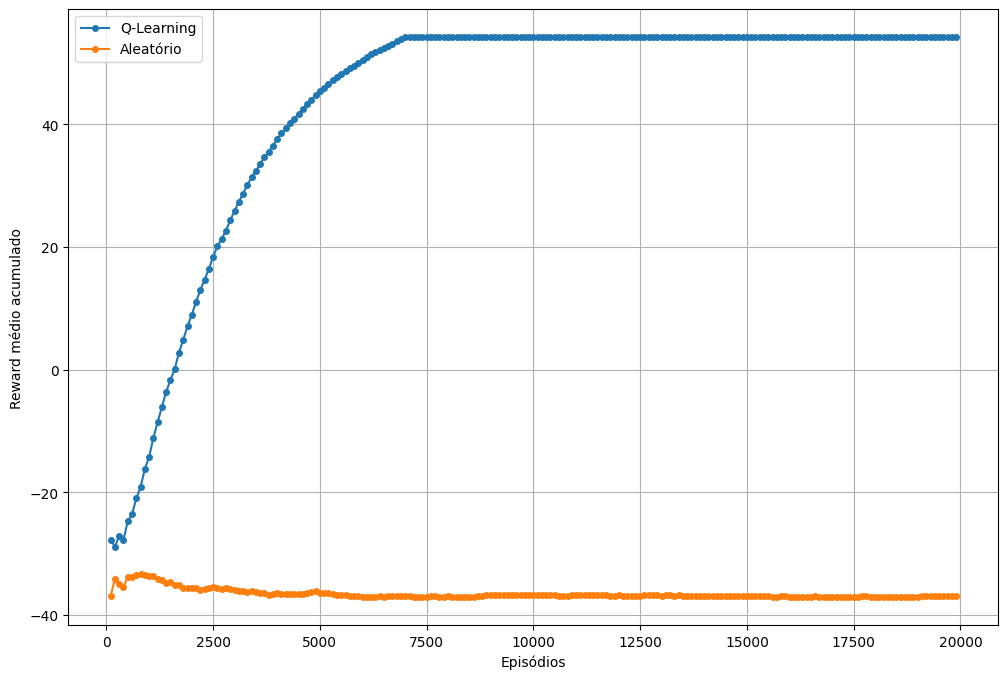

In [128]:
plt.figure(figsize=(12, 8))

plt.plot(
    range(100, 20000, 100),
    mean_rewards_trained,
    marker='o',
    markersize=4,
    label='Q-Learning'
)

plt.plot(
    range(100, 20000, 100),
    mean_rewards_random,
    marker='o',
    markersize=4,
    label='Aleatório'
)

plt.xlabel('Episódios')
plt.ylabel('Reward médio acumulado')
plt.legend()
plt.grid()

plt.show()

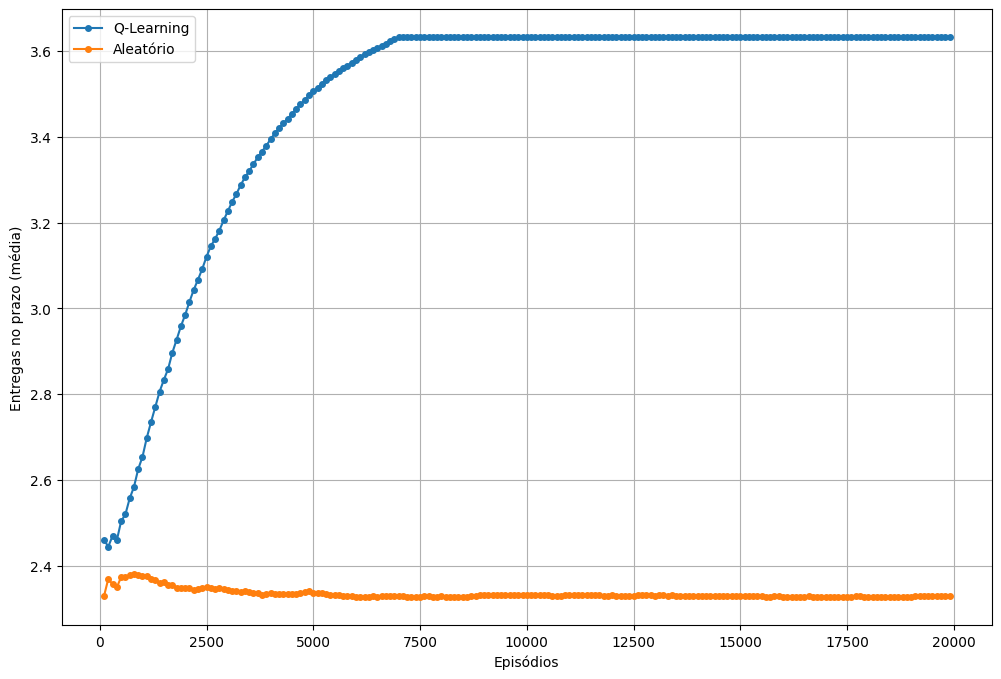

In [129]:
plt.figure(figsize=(12, 8))

plt.plot(
    range(100, 20000, 100),
    mean_deliveries_trained,
    marker='o',
    markersize=4,
    label='Q-Learning'
)

plt.plot(
    range(100, 20000, 100),
    mean_deliveries_random,
    marker='o',
    markersize=4,
    label='Aleatório'
)

plt.xlabel('Episódios')
plt.ylabel('Entregas no prazo (média)')
plt.legend()
plt.grid()

plt.show()